# Figure 6a. AD GWAS loci colocalized with TransMap QTL

UpSet plot of the 118 AD GWAS (Bellenguez et al.) colocalization signals detected by TransMap/ColocBoost at the AD target loci (`transmap_AD_target_results_pv1e4.tsv`), showing which of them also colocalize with a *cis*-eGene, a *trans*-eGene, a *trans*-eProgram (local program), a *trans*-biomarker (protein / glycoprotein / metabolite QTL), or overlap a cell-fraction QTL. Colocalization confidence sets (CoS) on the same chromosome that share at least 50% of the smaller CoS, or share the same top variant, are merged into one signal (237 CoS → 118 signals). The inset Venn diagram compares signals with any *cis*-eQTL (n = 87) against signals with any *trans*-QTL (eGene, eProgram, global program or biomarker; n = 115). Counts only; no statistical test is involved.

Input: `data/Figure_6a_ad_coloc_membership.rds` (one row per AD signal, logical membership columns).

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(ComplexUpset)
  library(patchwork)
})
mem <- readRDS("data/Figure_6a_ad_coloc_membership.rds")
head(mem)
colSums(mem[, c("AD_GWAS", "cis_eGene", "trans_eGene", "trans_eProgram",
                "trans_biomarker", "cell_fraction", "trans_QTL")])

,signal,chrom,top_variable,n_cos,AD_GWAS,cis_eGene,trans_eGene,trans_eProgram,trans_biomarker,cell_fraction,trans_QTL
,<dbl>,<chr>,<chr>,<int>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>
1,1,chr1,chr1:114365210:A:T,3,TRUE,FALSE,TRUE,TRUE,TRUE,FALSE,TRUE
2,2,chr1,chr1:161189357:C:T,2,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,TRUE
3,3,chr1,chr1:201012797:T:C,3,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,TRUE
4,4,chr1,chr1:207577223:T:C,2,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,TRUE
5,5,chr1,chr1:30754408:C:T,2,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,TRUE
6,6,chr10,chr10:100998580:G:T,3,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,TRUE


AD_GWAS       cis_eGene     trans_eGene  trans_eProgram trans_biomarker 
            118              87             114             105              81 
  cell_fraction       trans_QTL 
              0             115

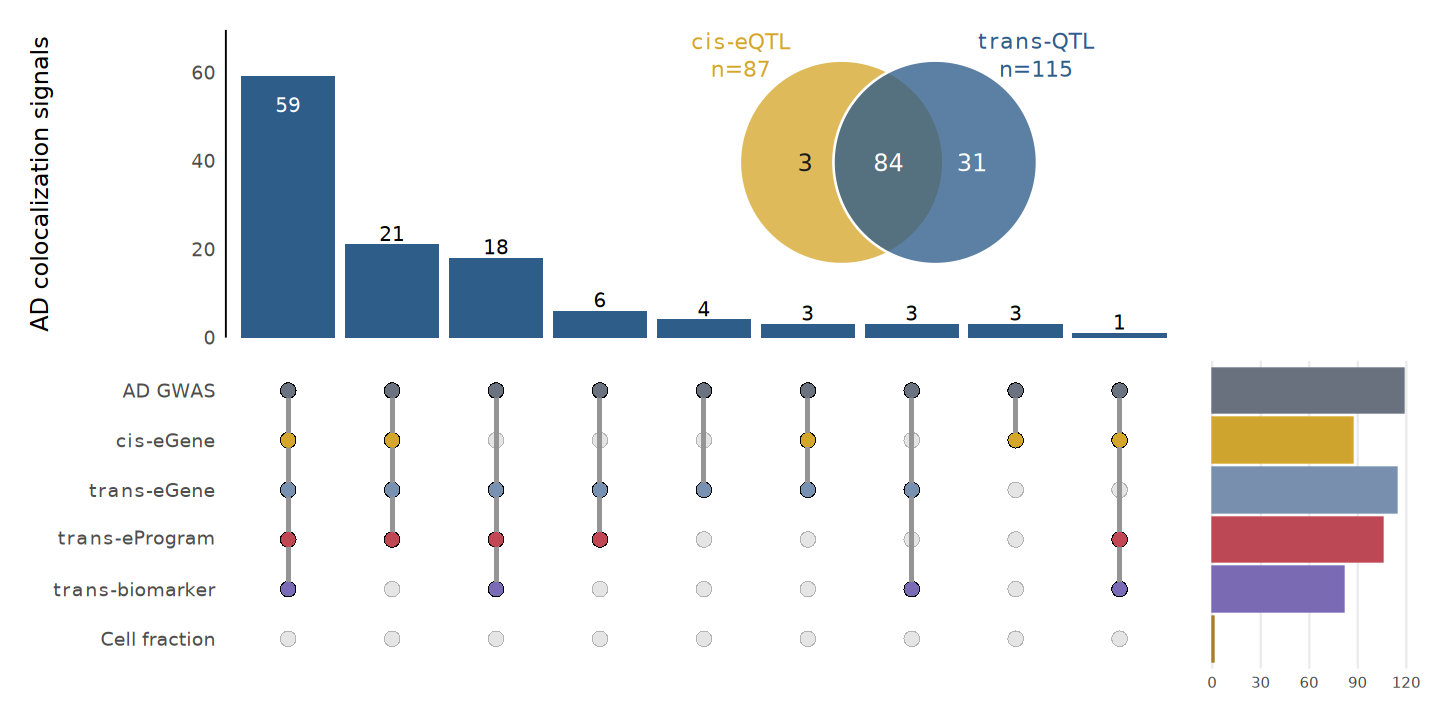

In [2]:
sets <- c("AD_GWAS", "cis_eGene", "trans_eGene", "trans_eProgram", "trans_biomarker", "cell_fraction")
set_colors <- c(AD_GWAS = "#6B7280", cis_eGene = "#D4A72C", trans_eGene = "#7991B1",
                trans_eProgram = "#C24755", trans_biomarker = "#7A6BB7", cell_fraction = "#A67C2D")
set_labels <- c(
  AD_GWAS         = expression(plain("AD") ~ plain("GWAS")),
  cis_eGene       = expression(italic(cis) * plain("-eGene")),
  trans_eGene     = expression(italic(trans) * plain("-eGene")),
  trans_eProgram  = expression(italic(trans) * plain("-eProgram")),
  trans_biomarker = expression(italic(trans) * plain("-biomarker")),
  cell_fraction   = expression(plain("Cell") ~ plain("fraction"))
)
sz <- 14

p_upset <- upset(
  mem, rev(sets),
  name = NULL,
  labeller = function(x) unname(set_labels[x]),
  min_size = 1, sort_sets = FALSE, sort_intersections_by = "cardinality",
  width_ratio = 0.18, height_ratio = c(1, 2), keep_empty_groups = TRUE,
  queries = lapply(sets, function(s) upset_query(set = s, fill = set_colors[[s]], color = set_colors[[s]])),
  matrix = intersection_matrix(
    geom = geom_point(shape = 16, size = 3.4),
    segment = geom_segment(linewidth = 0.8, color = "grey58")
  ) + scale_color_manual(values = c("TRUE" = "#2C3E50", "FALSE" = "#E5E5E5"), guide = "none"),
  set_sizes = upset_set_size(geom = geom_bar(alpha = 0.95), position = "right") +
    scale_fill_manual(values = set_colors, guide = "none") +
    labs(x = NULL, y = NULL) +
    theme(axis.text.y = element_blank(), axis.title = element_blank(),
          panel.grid.major.y = element_blank(), panel.grid.minor = element_blank()),
  base_annotations = list(
    "AD colocalization signals" = intersection_size(
      counts = TRUE, text = list(size = sz / 3.4, vjust = -0.25),
      mapping = aes(fill = "intersection")
    ) +
      scale_fill_manual(values = c(intersection = "#2F5D8A"), guide = "none") +
      scale_y_continuous(expand = expansion(mult = c(0, 0.18))) +
      labs(x = NULL, y = NULL) +
      theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(),
            panel.grid = element_blank(), axis.line.y = element_line(linewidth = 0.4))
  ),
  stripes = upset_stripes(geom = geom_segment(linewidth = 0), colors = c("white", "white")),
  themes = upset_modify_themes(list(
    default = theme_minimal(base_size = sz),
    intersections_matrix = theme_minimal(base_size = sz) +
      theme(axis.title = element_blank(), axis.text.x = element_blank(),
            panel.grid = element_blank())
  ))
)

# Venn: any cis-eQTL vs any trans-QTL
cis_only   <- sum(mem$cis_eGene & !mem$trans_QTL)
cis_trans  <- sum(mem$cis_eGene & mem$trans_QTL)
trans_only <- sum(!mem$cis_eGene & mem$trans_QTL)
circle_df <- function(cx, r, id) {
  th <- seq(0, 2 * pi, length.out = 360)
  data.frame(x = cx + r * cos(th), y = r * sin(th), set = id)
}
venn_df <- rbind(circle_df(-0.46, 1, "cis"), circle_df(0.46, 1, "trans"))
p_venn <- ggplot(venn_df, aes(x, y, group = set, fill = set)) +
  geom_polygon(color = "white", linewidth = 0.55, alpha = 0.78) +
  annotate("text", x = c(-0.82, 0, 0.82), y = 0, label = c(cis_only, cis_trans, trans_only),
           size = 5, color = c("grey10", "white", "white")) +
  annotate("text", x = c(-1.45, 1.45), y = 1.18, parse = TRUE, size = 4.5, color = c("#D4A72C", "#2F5D8A"),
           label = c("italic(cis)*'-eQTL'", "italic(trans)*'-QTL'")) +
  annotate("text", x = c(-1.45, 1.45), y = 0.92, size = 4.5, color = c("#D4A72C", "#2F5D8A"),
           label = paste0("n=", c(sum(mem$cis_eGene), sum(mem$trans_QTL)))) +
  scale_fill_manual(values = c(cis = "#D4A72C", trans = "#2F5D8A"), guide = "none") +
  coord_equal(xlim = c(-2.1, 2.1), ylim = c(-1.02, 1.3), clip = "off") +
  theme_void()

options(repr.plot.width = 12, repr.plot.height = 6)
wrap_elements(full = p_upset) +
  inset_element(p_venn, left = 0.42, bottom = 0.62, right = 0.82, top = 1.0)